# Session 5: Distribution Families and Continuous Random Variables

*ECE 225A, Module 01 (Probability Review), slides 70-89*

Sessions 3 and 4 built general tools: the PMF and CDF, the expectation, and the variance. This session applies them to a handful of distributions that come up so often they have names: **Bernoulli**, **binomial**, **Poisson**, and **geometric**. Each one is a *family* indexed by one or two parameters. Once you recognize that a random variable belongs to a family, its PMF, mean, and variance come for free. The second half moves from discrete to **continuous** random variables. The PMF becomes a density, sums become integrals, and almost every tool carries over unchanged. The session ends by finding the distribution of a function $Y = g(X)$ of a continuous variable, first with the CDF method and then with the change-of-variables formula.

## Learning objectives

After this session you should be able to:

1. Recognize when a random variable is Bernoulli, binomial, Poisson, or geometric, name its parameters, and spot the assumption (independence, a common $p$, a fixed number of trials) that breaks a model.
2. Derive the binomial PMF by counting sequences, and its mean $np$ and variance $npq$ by writing the count as a sum of indicators.
3. Check that the Poisson PMF sums to 1, derive its mean and variance $\lambda$, and show numerically that $B_{\lambda/n,\,n}$ approaches $P_\lambda$.
4. Derive the geometric PMF, CDF, mean, and variance, and prove and use memorylessness.
5. Translate between discrete and continuous models (PMF and PDF, sums and integrals, differences and derivatives), and explain why a density can exceed 1 even though $P(X = x) = 0$.
6. Compute expectations and variances of continuous variables, and apply the law of total expectation.
7. Find the PDF of $Y = g(X)$ with the CDF method and with the formula $\sum f_X(x)/\lvert g'(x) \rvert$, for monotone and for many-to-one maps.

## Prerequisites

- Binomial coefficients $\binom{n}{k}$ (Session 1).
- Independence and the product rule (Session 2).
- PMF, CDF, expectation, tail sums, LOTUS, linearity, and indicators (Session 3).
- Variance, $V(aX + b) = a^2 V(X)$, and the variance of a sum of independent variables (Session 4).
- Calculus: the geometric series and its derivatives, the series $e^x = \sum_{i \ge 0} x^i / i!$, the limit $(1 - \lambda/n)^n \to e^{-\lambda}$, basic integrals, and the chain rule.

In [1]:
from fractions import Fraction
from itertools import product
from math import comb, exp, factorial, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")


def E(pmf, g=lambda w: w):
    # LOTUS: E[g] = sum of g(w) p(w) over the outcomes w listed in the PMF.
    return sum((g(w) * p for w, p in pmf.items()), Fraction(0))


def Var(pmf, g=lambda w: w):
    # V = E[(g - mu)^2], straight from the definition.
    mu = E(pmf, g)
    return E(pmf, lambda w: (g(w) - mu) ** 2)


def stems(ax, xs, ps, color=BLUE, ms=6):
    # Draw a PMF as thin stems with dot heads.
    ax.vlines(xs, 0, ps, color=color, lw=2)
    ax.plot(xs, ps, "o", color=color, ms=ms, mec="white", mew=1.5)

## 1. The Bernoulli distribution (slides 70-71)

**Intuition.** The simplest random variable that is not a constant takes just two values, 0 and 1. Think of a single trial that either succeeds (1) or fails (0): a coin lands heads, a patient responds, a part is faulty. Every indicator $\mathbf{1}_A$ from Session 3 is a Bernoulli variable, and the rest of this session builds larger families out of such trials.

**Formal definition.** For a parameter $0 \le p \le 1$, a random variable $X$ is **Bernoulli $p$**, written $X \sim B_p$, if

$$p(1) = P(X = 1) = p, \qquad p(0) = P(X = 0) = 1 - p.$$

The failure probability $1 - p$ appears so often that it has its own names, $\bar{p}$ or $q$. One parameter determines the whole distribution.

**Mean, variance, std.** These were derived in Sessions 3 and 4. The key step is $X^2 = X$ (since $0^2 = 0$ and $1^2 = 1$):

$$\mu = 0 \cdot q + 1 \cdot p = p, \qquad V = E[X^2] - \mu^2 = p - p^2 = pq, \qquad \sigma = \sqrt{pq}.$$

The extreme cases $p = 0$ and $p = 1$ are constants, with $V = 0$.

**Example.** A player makes each free throw with probability $0.8$. One attempt is $X \sim B_{0.8}$, with $\mu = 0.8$, $V = 0.8 \cdot 0.2 = 0.16$, and $\sigma = 0.4$.

In [2]:
def bernoulli(p):
    return {0: 1 - p, 1: p}


p = Fraction(4, 5)
show("E[X]", E(bernoulli(p)))
show("V(X)", Var(bernoulli(p)))
print(f"std : {sqrt(Var(bernoulli(p))):.6f}")

shots = (rng.random(1_000_000) < 0.8).astype(int)
print(f"simulated: mean {shots.mean():.4f}, variance {shots.var():.4f}")

E[X]: 4/5 = 0.800000
V(X): 4/25 = 0.160000
std : 0.400000
simulated: mean 0.7998, variance 0.1601


## 2. The binomial distribution: counting successes (slides 72-73)

**Intuition.** Repeat a Bernoulli trial $n$ times, independently, with the same success probability $p$ each time, and count the successes. The count is a random variable, and its distribution is binomial. The standard picture: flip a coin with $P(\text{heads}) = p$ a total of $n$ times and count the heads.

**Formal definition.** Let $X_1, \dots, X_n$ be independent, each $\sim B_p$. The number of successes

$$X = X_1 + X_2 + \cdots + X_n$$

has the **binomial distribution** $B_{p,n}$, and we write $X \sim B_{p,n}$. (Many books write $\mathrm{Bin}(n, p)$, with the parameters in the other order.) For example, $B_{1/3,\,5}$ counts the successes in 5 trials with success probability $1/3$, and $B_{0.2,\,10}$ counts the successes in 10 trials with success probability $0.2$. With one trial, $B_{p,1} = B_p$.

**When is a count binomial?** It takes three conditions: (1) a fixed number $n$ of trials, (2) independent trials, and (3) the same success probability $p$ on every trial. Many real counts satisfy these at least approximately: patients who respond to a treatment, faulty components in a shipment, students who pass a test (or who get a B), voters for a given party in a random sample. The conditions decide whether the model fits:

| Count | Binomial? | Reason |
|---|---|---|
| Rainy weekends in a month | roughly | weekends are a week apart, so close to independent, and $p$ is similar within one month |
| Rainy days in a year | no | consecutive days are dependent (storms last several days), and $p$ changes with the season |
| Delayed flights on a normal day | roughly | delays of different flights are close to independent |
| Delayed flights on a stormy day | no | one storm delays many flights at once, so the trials are dependent |

The simulation below builds $B_{1/3,\,5}$ literally: each row is 5 independent trials, and $X$ is the row sum.

In [3]:
n, p = 5, 1 / 3
trials = rng.random((1_000_000, n)) < p      # each row: 5 independent B_1/3 trials
X = trials.sum(axis=1)                         # number of successes in each row
print("first three experiments (1 = success):")
for row, x in zip(trials[:3].astype(int), X[:3]):
    print("  ", row, "-> X =", x)
print("values taken:", np.unique(X))

first three experiments (1 = success):
   [0 0 0 1 1] -> X = 2
   [1 0 0 0 1] -> X = 2
   [0 1 1 0 0] -> X = 2
values taken: [0 1 2 3 4 5]


## 3. The binomial PMF (slide 74)

**Derivation.** $X \sim B_{p,n}$ takes the $n + 1$ values $0, 1, \dots, n$. Fix one of them, $k$. An outcome of the experiment is a sequence of $n$ results such as $SFSSF$. Two observations give the PMF.

1. **Every sequence with exactly $k$ successes has probability $p^k q^{n-k}$.** By independence, the probability of a sequence is the product of the probabilities of its results: $p$ for each of the $k$ successes and $q$ for each of the $n - k$ failures. Only the counts matter, not the order.
2. **There are $\binom{n}{k}$ such sequences**, one for each choice of the $k$ positions (out of $n$) that hold the successes.

Adding $\binom{n}{k}$ equal probabilities gives

$$b_{p,n}(k) = P(X = k) = \binom{n}{k} p^k q^{n-k}, \qquad k = 0, 1, \dots, n.$$

The binomial coefficient gives the distribution its name. The PMF sums to 1 by the binomial theorem: $\sum_{k=0}^{n} \binom{n}{k} p^k q^{n-k} = (p + q)^n = 1$.

**Example: $B_{1/3,\,5}$.** For $k = 2$,

$$b_{1/3,5}(2) = \binom{5}{2} \left(\frac{1}{3}\right)^2 \left(\frac{2}{3}\right)^3 = 10 \cdot \frac{1}{9} \cdot \frac{8}{27} = \frac{80}{243} \approx 0.329.$$

Over a common denominator of $3^5 = 243$, the numerator for each $k$ is $\binom{5}{k} 2^{5-k}$:

| $k$ | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| $b_{1/3,5}(k)$ | $32/243$ | $80/243$ | $80/243$ | $40/243$ | $10/243$ | $1/243$ |

The numerators add to $243$, as they must. The code checks the formula against a brute-force sum over all $2^5 = 32$ sequences and against the simulation above.

In [4]:
def binomial(n, p):
    # b_{p,n}(k) = C(n, k) p^k q^(n - k), exact when p is a Fraction.
    return {k: comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n + 1)}


n, p = 5, Fraction(1, 3)
pmf = binomial(n, p)

# Brute force: add up the probabilities of all 2^5 success/failure sequences, grouped by number of successes.
brute = {k: Fraction(0) for k in range(n + 1)}
for seq in product([0, 1], repeat=n):
    k = sum(seq)
    brute[k] += p ** k * (1 - p) ** (n - k)
assert brute == pmf and sum(pmf.values()) == 1

print(" k   exact              simulated")
for k in range(n + 1):
    print(f" {k}   {str(pmf[k]):>7} = {float(pmf[k]):.4f}   {np.mean(X == k):.4f}")

 k   exact              simulated
 0    32/243 = 0.1317   0.1314
 1    80/243 = 0.3292   0.3285
 2    80/243 = 0.3292   0.3296
 3    40/243 = 0.1646   0.1651
 4    10/243 = 0.0412   0.0414
 5     1/243 = 0.0041   0.0041


## 4. Shapes of the binomial PMF (slide 75)

Fix $n = 20$ coin flips and vary $P(\text{heads}) = p$. Each panel shows $b_{p,20}(k)$, the probability of $k$ heads, with the mean $np$ marked by a dashed line.

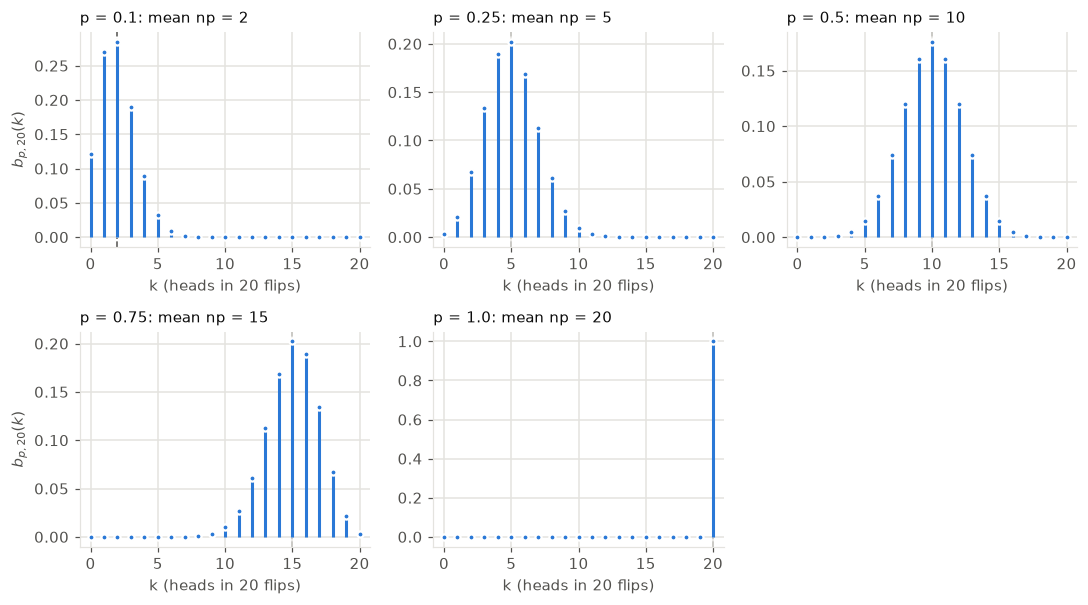

In [5]:
n = 20
ks = np.arange(n + 1)
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
for ax, p_ in zip(axes.flat, [0.1, 0.25, 0.5, 0.75, 1.0]):
    probs = [comb(n, k) * p_ ** k * (1 - p_) ** (n - k) for k in ks]
    stems(ax, ks, probs, ms=4)
    ax.axvline(n * p_, color=MUTED, lw=1, ls="--", zorder=0)
    ax.set(xlim=(-0.8, 20.8), xticks=range(0, 21, 5), xlabel="k (heads in 20 flips)")
    ax.set_title(f"p = {p_}: mean np = {n * p_:g}", color=INK, loc="left", fontsize=10)
axes[1, 2].axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("$b_{p,20}(k)$")
plt.tight_layout()
plt.show()

What the panels show:

- **The peak sits next to the mean $np$** (at $k = 2, 5, 10, 15, 20$).
- **At $p = 1/2$ the PMF is symmetric** about $n/2 = 10$.
- **$p = 0.75$ mirrors $p = 0.25$.** Counting failures instead of successes swaps the roles of $p$ and $q$, so $n - X \sim B_{q,n}$ and $b_{p,n}(k) = b_{q,n}(n - k)$.
- **For small $p$ the PMF is pushed against 0 and skewed to the right.** At $p = 1$ it is the constant 20.
- **The spread is largest at $p = 1/2$**, which matches the variance $npq$ derived in the next section.

In [6]:
n = 20
for p_ in [Fraction(1, 10), Fraction(1, 4), Fraction(1, 2)]:
    b, b_mirror = binomial(n, p_), binomial(n, 1 - p_)
    assert all(b[k] == b_mirror[n - k] for k in range(n + 1))
    mode = max(b, key=b.get)
    print(f"p = {str(p_):>4}: most likely k = {mode:2d}, mean np = {float(n * p_):g}")
print("b_{p,n}(k) = b_{q,n}(n - k) holds exactly: counting failures swaps p and q")

p = 1/10: most likely k =  2, mean np = 2
p =  1/4: most likely k =  5, mean np = 5
p =  1/2: most likely k = 10, mean np = 10
b_{p,n}(k) = b_{q,n}(n - k) holds exactly: counting failures swaps p and q


## 5. Binomial mean and variance via indicators (slide 76)

Write $X \sim B_{p,n}$ as $X = \sum_{i=1}^{n} X_i$, where $X_i$ is the indicator that trial $i$ succeeds. The $X_i$ are independent and each $X_i \sim B_p$.

**Mean, by linearity.**

$$E[X] = E\Big[\sum_{i=1}^{n} X_i\Big] = \sum_{i=1}^{n} E[X_i] = \sum_{i=1}^{n} p = np.$$

Linearity needs no independence, so this step would hold for any $n$ trials with success probability $p$ each.

**Variance, by independence.** Independent variables are uncorrelated, so every covariance term vanishes and the variances add (Session 4):

$$V(X) = V\Big(\sum_{i=1}^{n} X_i\Big) = \sum_{i=1}^{n} V(X_i) = \sum_{i=1}^{n} pq = npq, \qquad \sigma = \sqrt{npq}.$$

This step does use independence.

Computing $E[X] = \sum_k k \binom{n}{k} p^k q^{n-k}$ directly is also possible, but it needs a binomial-coefficient identity (Exercise 7). The indicator route takes one line.

**Example: $B_{0.2,\,10}$.** $\mu = 10 \cdot 0.2 = 2$, $V = 10 \cdot 0.2 \cdot 0.8 = 1.6$, and $\sigma = \sqrt{1.6} \approx 1.265$. For $B_{1/3,\,5}$: $\mu = 5/3$ and $V = 10/9$. In the $n = 20$ panels, $\sigma = \sqrt{5} \approx 2.24$ at $p = 1/2$ but only $\sqrt{1.8} \approx 1.34$ at $p = 0.1$.

In [7]:
for n_ in range(1, 13):
    for p_ in [Fraction(1, 5), Fraction(1, 3), Fraction(1, 2), Fraction(7, 10)]:
        b = binomial(n_, p_)
        assert E(b) == n_ * p_ and Var(b) == n_ * p_ * (1 - p_)
print("E[X] = np and V(X) = npq hold exactly for n = 1..12 and every p tried\n")

n, p = 10, Fraction(1, 5)
show("B_0.2,10: np ", n * p)
show("B_0.2,10: npq", n * p * (1 - p))
X10 = (rng.random((1_000_000, n)) < 0.2).sum(axis=1)
print(f"simulated: mean {X10.mean():.4f}, variance {X10.var():.4f}, std {X10.std():.4f} (exact std {sqrt(1.6):.4f})")

E[X] = np and V(X) = npq hold exactly for n = 1..12 and every p tried

B_0.2,10: np : 2 = 2.000000
B_0.2,10: npq: 8/5 = 1.600000
simulated: mean 2.0005, variance 1.5942, std 1.2626 (exact std 1.2649)


**Independence matters for the variance, not for the mean.** At the other extreme from independence, let all ten "trials" be copies of one $B_{0.2}$ trial, so $X = 10 X_1$. The mean is still $np = 2$, but $V(X) = 100\, V(X_1) = n^2 pq = 16$, ten times the binomial variance.

In [8]:
copies = 10 * (rng.random(1_000_000) < 0.2)     # one B_0.2 trial, copied ten times
print(f"copied trial: mean {copies.mean():.4f} (np = 2), variance {copies.var():.4f} (n^2 pq = 16, not npq = 1.6)")

copied trial: mean 1.9991 (np = 2), variance 15.9944 (n^2 pq = 16, not npq = 1.6)


## 6. The Poisson distribution (slide 77)

**Intuition.** The Poisson distribution models counts of rare events in a fixed window when there are very many chances for an event to happen: typos on a page, calls to a help line in a minute, radioactive decays in a second. The count has no fixed upper limit, so this is the first family with an **infinite support**.

**Formal definition.** For a parameter $\lambda \ge 0$, $X \sim P_\lambda$ ("Poisson $\lambda$") if

$$P_\lambda(k) = P(X = k) = e^{-\lambda} \frac{\lambda^k}{k!}, \qquad k \in \mathbb{N} = \lbrace 0, 1, 2, \dots \rbrace.$$

This is a valid PMF. Every term is nonnegative, and by the series $e^x = \sum_{i \ge 0} x^i / i!$,

$$\sum_{k=0}^{\infty} e^{-\lambda} \frac{\lambda^k}{k!} = e^{-\lambda} e^{\lambda} = 1.$$

The parameter $\lambda$ is the mean (Section 7). With $\lambda = 0$, $X$ is the constant 0.

**Significance.** $P_\lambda$ approximates $B_{p,n}$ when $n$ is large and $p$ is small, so that $np = \lambda$ is moderate (Section 8). That is why it fits rare events among many chances.

**Shape.** The ratio of consecutive terms is

$$\frac{P_\lambda(k)}{P_\lambda(k - 1)} = \frac{\lambda}{k}.$$

So the PMF rises while $k < \lambda$ and falls once $k > \lambda$, and it peaks at $\lfloor \lambda \rfloor$. When $\lambda$ is an integer, the ratio at $k = \lambda$ equals 1, so there is a tie: $P_\lambda(\lambda - 1) = P_\lambda(\lambda)$. For $\lambda = 1$, $P(0) = P(1) = e^{-1} \approx 0.368$. For $\lambda = 4$, $P(3) = P(4) = \frac{32}{3} e^{-4} \approx 0.195$.

In [9]:
def poisson(lam, k):
    return exp(-lam) * lam ** k / factorial(k)


for lam in [1, 4, 10]:
    total = sum(poisson(lam, k) for k in range(100))   # terms past k = 100 are below 1e-60 here
    assert all(abs(poisson(lam, k) / poisson(lam, k - 1) - lam / k) < 1e-12 for k in range(1, 40))
    print(f"lambda = {lam:2d}: sum of PMF = {total:.12f},   "
          f"P({lam - 1}) = {poisson(lam, lam - 1):.6f} = P({lam}) = {poisson(lam, lam):.6f}")

lambda =  1: sum of PMF = 1.000000000000,   P(0) = 0.367879 = P(1) = 0.367879
lambda =  4: sum of PMF = 1.000000000000,   P(3) = 0.195367 = P(4) = 0.195367
lambda = 10: sum of PMF = 1.000000000000,   P(9) = 0.125110 = P(10) = 0.125110


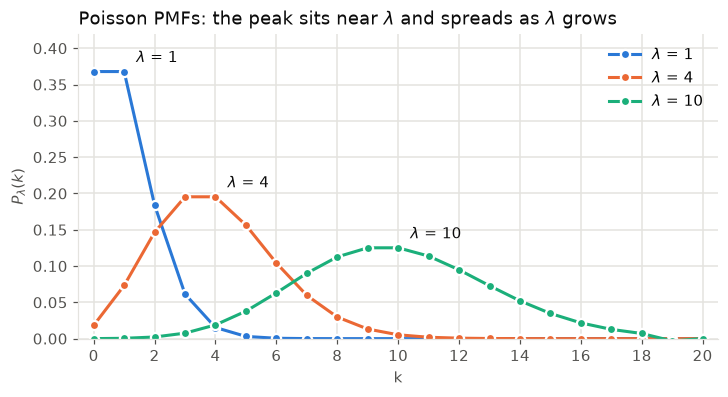

In [10]:
ks = np.arange(21)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for lam, color in zip([1, 4, 10], [BLUE, ORANGE, AQUA]):
    ax.plot(ks, [poisson(lam, k) for k in ks], "-o", color=color, lw=2, ms=6, mec="white", mew=1.5,
            label=f"$\\lambda$ = {lam}")
    ax.annotate(f"$\\lambda$ = {lam}", xy=(lam, poisson(lam, lam)), xytext=(8, 6), textcoords="offset points", color=INK)
ax.set(xlim=(-0.5, 20.5), ylim=(0, 0.42), xticks=range(0, 21, 2), xlabel="k", ylabel="$P_\\lambda(k)$")
ax.legend(frameon=False)
ax.set_title("Poisson PMFs: the peak sits near $\\lambda$ and spreads as $\\lambda$ grows", color=INK, loc="left")
plt.show()

## 7. Poisson mean and variance (slide 78)

**Mean.** Start from the definition and simplify one step at a time:

$$
\begin{aligned}
E[X] &= \sum_{k=0}^{\infty} k\, e^{-\lambda} \frac{\lambda^k}{k!}
= e^{-\lambda} \sum_{k=1}^{\infty} k \frac{\lambda^k}{k!} && \text{(the } k = 0 \text{ term is 0)} \\
&= \lambda e^{-\lambda} \sum_{k=1}^{\infty} \frac{\lambda^{k-1}}{(k-1)!} && \text{(cancel } k \text{ against } k! \text{, pull out one } \lambda) \\
&= \lambda e^{-\lambda} \sum_{\ell=0}^{\infty} \frac{\lambda^{\ell}}{\ell!} && (\ell = k - 1) \\
&= \lambda e^{-\lambda} e^{\lambda} = \lambda.
\end{aligned}
$$

So $\lambda$ is the natural parameter of the family: it is the mean.

**Variance.** Computing $E[X^2]$ directly gets stuck, because $k^2$ does not cancel against $k!$. The trick is to compute $E[X(X-1)]$ instead, since $k(k-1)$ does cancel:

$$E[X(X - 1)] = \sum_{k=2}^{\infty} k(k-1)\, e^{-\lambda} \frac{\lambda^k}{k!} = \lambda^2 e^{-\lambda} \sum_{k=2}^{\infty} \frac{\lambda^{k-2}}{(k-2)!} = \lambda^2 e^{-\lambda} e^{\lambda} = \lambda^2.$$

Then $E[X^2] = E[X(X-1)] + E[X] = \lambda^2 + \lambda$, so

$$V(X) = \lambda^2 + \lambda - \lambda^2 = \lambda, \qquad \sigma = \sqrt{\lambda}.$$

A Poisson count has **mean equal to variance**. That gives a quick check on whether count data could be Poisson.

In [11]:
for lam in [0.5, 1, 4, 10]:
    terms = [(k, poisson(lam, k)) for k in range(100)]   # truncated: the tail past 100 is negligible
    mean = sum(k * pk for k, pk in terms)
    fact2 = sum(k * (k - 1) * pk for k, pk in terms)
    var = fact2 + mean - mean ** 2
    sample = rng.poisson(lam, size=1_000_000)
    print(f"lambda = {lam:4}: E[X] = {mean:.6f}, E[X(X-1)] = {fact2:8.4f} (lambda^2 = {lam ** 2:g}), V = {var:.6f};"
          f"  simulated mean {sample.mean():.4f}, var {sample.var():.4f}")

lambda =  0.5: E[X] = 0.500000, E[X(X-1)] =   0.2500 (lambda^2 = 0.25), V = 0.500000;  simulated mean 0.5002, var 0.5000
lambda =    1: E[X] = 1.000000, E[X(X-1)] =   1.0000 (lambda^2 = 1), V = 1.000000;  simulated mean 0.9985, var 0.9978
lambda =    4: E[X] = 4.000000, E[X(X-1)] =  16.0000 (lambda^2 = 16), V = 4.000000;  simulated mean 4.0022, var 4.0137
lambda =   10: E[X] = 10.000000, E[X(X-1)] = 100.0000 (lambda^2 = 100), V = 10.000000;  simulated mean 10.0000, var 10.0017


## 8. The Poisson as a limit of binomials (slide 77, "more in notebook")

Fix $\lambda$ and let the number of trials grow while the success probability shrinks, $p = \lambda/n$, so that the mean $np = \lambda$ stays put. For each fixed $k$,

$$
b_{\lambda/n,\,n}(k) = \binom{n}{k} \left(\frac{\lambda}{n}\right)^k \left(1 - \frac{\lambda}{n}\right)^{n-k}
= \frac{\lambda^k}{k!} \cdot \underbrace{\frac{n(n-1)\cdots(n-k+1)}{n^k}}_{\to\, 1} \cdot \underbrace{\left(1 - \frac{\lambda}{n}\right)^{n}}_{\to\, e^{-\lambda}} \cdot \underbrace{\left(1 - \frac{\lambda}{n}\right)^{-k}}_{\to\, 1}
\;\longrightarrow\; e^{-\lambda} \frac{\lambda^k}{k!}.
$$

- The first bracket is a product of $k$ factors $\frac{n - j}{n} = 1 - \frac{j}{n}$, and each one tends to 1 because $k$ is fixed.
- The second bracket is the standard limit that defines $e^{-\lambda}$.
- The third bracket is a fixed power of a quantity that tends to 1.

The moments agree in the limit too: $np = \lambda$ exactly, and $npq = \lambda(1 - \lambda/n) \to \lambda$.

**Numerical check.** Take $\lambda = 3$. For growing $n$, the table compares $B_{3/n,\,n}$ with $P_3$ by the largest pointwise gap and by the **total variation distance** $\frac{1}{2} \sum_k \lvert b(k) - P_3(k) \rvert$. That distance is the largest possible difference between the two models' probabilities for any event. (For large $n$ the binomial terms come from the ratio $b(k)/b(k-1) = \frac{n - k + 1}{k} \cdot \frac{p}{q}$, which avoids huge binomial coefficients. Terms beyond $k = 60$ are below $10^{-50}$ for both models and are dropped.)

In [12]:
lam, K = 3, 60
ks = np.arange(K + 1)
pois3 = np.array([poisson(lam, k) for k in ks])


def binomial_floats(n, p):
    # b_{p,n}(k) for k = 0..K from the ratio b(k)/b(k-1) = (n - k + 1)/k * p/q; zero for k > n.
    probs = np.zeros(K + 1)
    probs[0] = (1 - p) ** n
    for k in range(1, min(n, K) + 1):
        probs[k] = probs[k - 1] * (n - k + 1) / k * p / (1 - p)
    return probs


ns_tv = [5, 10, 20, 50, 100, 1000, 10_000, 100_000]
tvs = []
print("      n   p = 3/n   max |b(k) - P(k)|   total variation   n x TV")
for n in ns_tv:
    gap = np.abs(binomial_floats(n, lam / n) - pois3)
    tvs.append(gap.sum() / 2)
    print(f"{n:>7}   {lam / n:7.5f}   {gap.max():17.6f}   {tvs[-1]:15.6f}   {n * tvs[-1]:6.3f}")

      n   p = 3/n   max |b(k) - P(k)|   total variation   n x TV
      5   0.60000            0.121558          0.219085    1.095
     10   0.30000            0.042786          0.086409    0.864
     20   0.15000            0.018787          0.040200    0.804
     50   0.06000            0.007015          0.015422    0.771
    100   0.03000            0.003432          0.007607    0.761
   1000   0.00300            0.000337          0.000752    0.752
  10000   0.00030            0.000034          0.000075    0.751
 100000   0.00003            0.000003          0.000008    0.751


The distance shrinks in proportion to $1/n$: the last column, $n$ times the distance, settles near a constant. Ten times as many trials (each ten times rarer) gives a Poisson approximation about ten times better. With few trials and a large $p$, though, the approximation is poor: at $n = 5$, $p = 0.6$, the two models disagree by about 0.2 on some events.

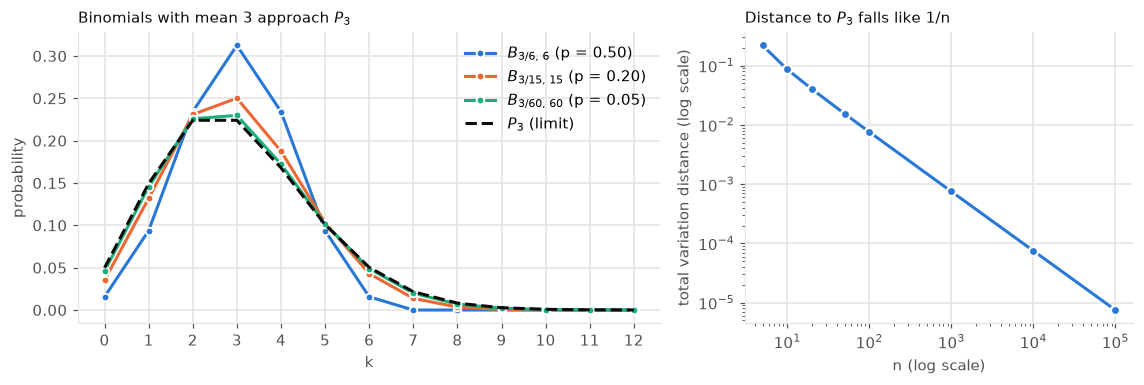

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
for n, color in zip([6, 15, 60], [BLUE, ORANGE, AQUA]):
    ax1.plot(ks[:13], binomial_floats(n, lam / n)[:13], "-o", color=color, lw=2, ms=5, mec="white", mew=1.2,
             label=f"$B_{{3/{n},\\,{n}}}$ (p = {lam / n:.2f})")
ax1.plot(ks[:13], pois3[:13], "--", color=INK, lw=2, label="$P_3$ (limit)")
ax1.set(xlabel="k", ylabel="probability", xticks=range(13))
ax1.legend(frameon=False)
ax1.set_title("Binomials with mean 3 approach $P_3$", color=INK, loc="left", fontsize=10)

ax2.loglog(ns_tv, tvs, "o-", color=BLUE, lw=2, ms=6, mec="white", mew=1.5)
ax2.set(xlabel="n (log scale)", ylabel="total variation distance (log scale)")
ax2.set_title("Distance to $P_3$ falls like 1/n", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

**Example.** A printer jams on each page independently with probability $0.001$, and it prints $3000$ pages a week. The exact count is $B_{0.001,\,3000}$, and the Poisson model with $\lambda = 3000 \cdot 0.001 = 3$ gives

$$P(\text{no jams}) \approx e^{-3} \approx 0.0498, \qquad P(\text{at most 2 jams}) \approx e^{-3}\left(1 + 3 + \frac{9}{2}\right) = 8.5\, e^{-3} \approx 0.4232.$$

In [14]:
b_jam = binomial_floats(3000, 0.001)
print(f"P(no jams):     binomial {b_jam[0]:.6f}   Poisson {pois3[0]:.6f}")
print(f"P(at most 2):   binomial {b_jam[:3].sum():.6f}   Poisson {pois3[:3].sum():.6f}")

P(no jams):     binomial 0.049712   Poisson 0.049787
P(at most 2):   binomial 0.423078   Poisson 0.423190


## 9. The geometric distribution (slide 79)

**Intuition.** Repeat independent $B_p$ trials until the first success, and count the trials, including the successful one. Again there is no upper limit, so the support is the positive integers $\lbrace 1, 2, 3, \dots \rbrace$.

**Formal definition.** For $0 < p \le 1$, $X \sim G_p$ ("geometric $p$") if

$$P(X = n) = q^{n-1} p, \qquad n \ge 1.$$

**Derivation.** $X = n$ exactly when trials $1, \dots, n - 1$ fail and trial $n$ succeeds, the sequence $F F \cdots F S$. By independence its probability is $q^{n-1} p$. The parameter must be positive: with $p = 0$ the first success never comes.

**It is a valid PMF.** By the geometric series (which names the family),

$$\sum_{n=1}^{\infty} q^{n-1} p = p \cdot \frac{1}{1 - q} = \frac{p}{p} = 1.$$

**Shape.** Each term is $q$ times the previous one, so the PMF always decreases. The most likely value is always $n = 1$, however small $p$ is. A larger $p$ makes it decay faster.

**Example.** Roll a die until the first six: $X \sim G_{1/6}$, and

$$P(X = 3) = \left(\frac{5}{6}\right)^2 \cdot \frac{1}{6} = \frac{25}{216} \approx 0.116.$$

In [15]:
def geometric(p, n):
    # P(X = n) = q^(n - 1) p: n - 1 failures, then the first success.
    return (1 - p) ** (n - 1) * p


p = Fraction(1, 6)
show("die, P(X = 3)", geometric(p, 3))
N = 60
assert sum(geometric(p, n) for n in range(1, N + 1)) == 1 - (1 - p) ** N   # partial sums climb to 1
first_six = rng.geometric(1 / 6, size=1_000_000)    # numpy counts trials up to and including the success
print(f"simulated P(X = 3): {np.mean(first_six == 3):.4f}")

die, P(X = 3): 25/216 = 0.115741
simulated P(X = 3): 0.1161


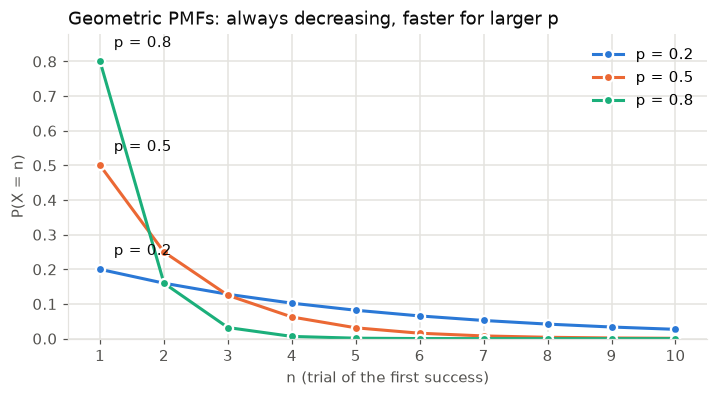

In [16]:
ns = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for p_, color in zip([0.2, 0.5, 0.8], [BLUE, ORANGE, AQUA]):
    ax.plot(ns, [geometric(p_, n) for n in ns], "-o", color=color, lw=2, ms=6, mec="white", mew=1.5, label=f"p = {p_}")
    ax.annotate(f"p = {p_}", xy=(1, p_), xytext=(9, 7), textcoords="offset points", va="bottom", color=INK)
ax.set(xlim=(0.5, 10.5), ylim=(0, 0.88), xticks=ns, xlabel="n (trial of the first success)", ylabel="P(X = n)")
ax.legend(frameon=False)
ax.set_title("Geometric PMFs: always decreasing, faster for larger p", color=INK, loc="left")
plt.show()

## 10. Geometric waiting times in practice (slide 80)

The geometric distribution models **attempts until the first occurrence** of some event. The event is called a "success" even when it is unwelcome:

- **Welcome events:** shots until the first hit on a target, experiments until a cure works, dates until meeting a future spouse (or, in the fairy tale, frogs kissed until one turns into a prince).
- **Unwelcome events:** days until a first car crash, sessions until a computer crashes, trips until a first traffic ticket.

In each case the model assumes independent attempts with the same $p$, which real life only approximates.

**The thief and the keys.** A ring holds $10$ keys, and exactly one opens the door. How many tries does it take?

- **A hurried thief** grabs a random key each time and may try the same wrong key again. The tries are independent with success probability $1/10$, so the number of tries is $G_{1/10}$, with mean $10$.
- **A methodical person** fumbling with their own ring sets each wrong key aside. The tries are no longer independent (each failure raises the chance of success on the next try), so this is **not** geometric. The right key is equally likely to sit in each of the 10 positions of the trial order, so the number of tries is uniform on $\lbrace 1, \dots, 10 \rbrace$, with mean $11/2$.

hurried thief:     mean tries 10.009   (exact 1/p = 10)
methodical person: mean tries 5.510   (exact 11/2 = 5.5),  max 10


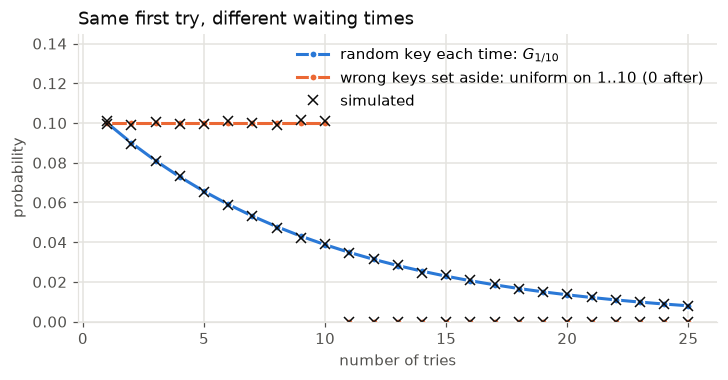

In [17]:
k_keys, runs = 10, 200_000
hurried = rng.geometric(1 / k_keys, size=runs)
# Methodical: a random order of the 10 keys (key 0 opens the door); count tries up to key 0.
orders = rng.permuted(np.tile(np.arange(k_keys), (runs, 1)), axis=1)
methodical = np.argmax(orders == 0, axis=1) + 1
print(f"hurried thief:     mean tries {hurried.mean():.3f}   (exact 1/p = 10)")
print(f"methodical person: mean tries {methodical.mean():.3f}   (exact 11/2 = 5.5),  max {methodical.max()}")

ns = np.arange(1, 26)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(ns, [geometric(0.1, n) for n in ns], "-o", color=BLUE, lw=2, ms=5, mec="white", mew=1.2,
        label="random key each time: $G_{1/10}$")
ax.plot(ns[:10], [0.1] * 10, "-o", color=ORANGE, lw=2, ms=5, mec="white", mew=1.2,
        label="wrong keys set aside: uniform on 1..10 (0 after)")
ax.plot(ns[10:], [0] * 15, "o", color=ORANGE, ms=5, mec="white", mew=1.2)
ax.plot(ns, [np.mean(hurried == n) for n in ns], "x", color=INK, ms=6, label="simulated")
ax.plot(ns, [np.mean(methodical == n) for n in ns], "x", color=INK, ms=6)
ax.set(xlabel="number of tries", ylabel="probability", ylim=(0, 0.145))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Same first try, different waiting times", color=INK, loc="left")
plt.show()

## 11. Geometric properties: CDF, mean, variance, memorylessness (slide 81)

Let $X \sim G_p$ with $q = 1 - p$.

**Tail and CDF.** $X > n$ means the first $n$ trials all fail, so

$$P(X > n) = q^n, \qquad F(n) = P(X \le n) = 1 - q^n, \qquad n = 0, 1, 2, \dots$$

**Mean, by tail sums** (Session 3, for variables in $\lbrace 0, 1, 2, \dots \rbrace$):

$$E[X] = \sum_{i=1}^{\infty} P(X \ge i) = \sum_{i=1}^{\infty} P(X > i - 1) = \sum_{i=1}^{\infty} q^{i-1} = \frac{1}{1 - q} = \frac{1}{p}.$$

A success with probability $1/6$ takes 6 tries on average, as intuition suggests.

**Variance.** As for the Poisson, compute $E[X(X-1)]$ first. Differentiating $\sum_{n \ge 0} q^n = \frac{1}{1 - q}$ twice with respect to $q$ gives $\sum_{n \ge 2} n(n-1) q^{n-2} = \frac{2}{(1 - q)^3}$, so

$$E[X(X - 1)] = \sum_{n=2}^{\infty} n(n-1)\, q^{n-1} p = pq \cdot \frac{2}{(1 - q)^3} = \frac{2q}{p^2}.$$

Then $E[X^2] = \frac{2q}{p^2} + \frac{1}{p}$, and

$$V(X) = \frac{2q}{p^2} + \frac{1}{p} - \frac{1}{p^2} = \frac{2q + p - 1}{p^2} = \frac{q}{p^2}, \qquad \sigma = \frac{\sqrt{q}}{p} \approx \frac{1}{p} \text{ for small } p.$$

For a rare success, the std is about as large as the mean, so waiting times are very unpredictable.

**Example: rolling until the first six.** $\mu = 6$, $V = \frac{5/6}{1/36} = 30$, and $\sigma = \sqrt{30} \approx 5.48$.

In [18]:
pf = Fraction(1, 6)
show("mean 1/p    ", 1 / pf)
show("var  q/p^2  ", (1 - pf) / pf ** 2)

p, q = 1 / 6, 5 / 6
ns = np.arange(1, 3001)
pmf_g = q ** (ns - 1) * p
print(f"F(4): sum of PMF {pmf_g[:4].sum():.6f}, 1 - q^4 = {1 - q ** 4:.6f}")
print(f"E[X]: definition {(ns * pmf_g).sum():.6f}, tail sums {sum(q ** (i - 1) for i in range(1, 3001)):.6f}")
print(f"V(X): definition {((ns - 6) ** 2 * pmf_g).sum():.6f}")
print(f"simulated: mean {first_six.mean():.4f}, variance {first_six.var():.4f}\n")

for p_ in [0.5, 0.1, 0.01]:
    print(f"p = {p_:4}: sigma = sqrt(q)/p = {sqrt(1 - p_) / p_:7.3f}   1/p = {1 / p_:5.0f}")

mean 1/p    : 6 = 6.000000
var  q/p^2  : 30 = 30.000000
F(4): sum of PMF 0.517747, 1 - q^4 = 0.517747
E[X]: definition 6.000000, tail sums 6.000000
V(X): definition 30.000000
simulated: mean 6.0023, variance 30.0265

p =  0.5: sigma = sqrt(q)/p =   1.414   1/p =     2
p =  0.1: sigma = sqrt(q)/p =   9.487   1/p =    10
p = 0.01: sigma = sqrt(q)/p =  99.499   1/p =   100


**Memorylessness.** For integers $n \ge 0$ and $m \ge 1$,

$$P(X = n + m \mid X > n) = \frac{P(X = n + m)}{P(X > n)} = \frac{q^{n+m-1} p}{q^n} = q^{m-1} p = P(X = m).$$

(The event $\lbrace X = n + m \rbrace$ lies inside $\lbrace X > n \rbrace$, so their intersection is $\lbrace X = n + m \rbrace$.) In words: given $n$ failures so far, the number of additional trials $X - n$ is again $G_p$. Past failures do not make a success "due". Believing they do is the gambler's fallacy. An equivalent form compares tails: $P(X > n + m \mid X > n) = q^{n+m}/q^n = q^m = P(X > m)$.

The check below conditions the die simulation on "no six in the first 5 rolls" and looks at the number of extra rolls.

P(X = n + m | X > n) = P(X = m) exactly for every n, m tried
402452 runs had no six in 5 rolls; extra rolls: mean 5.9981 (1/p = 6), P(extra = 1) = 0.1674 (p = 0.1667)


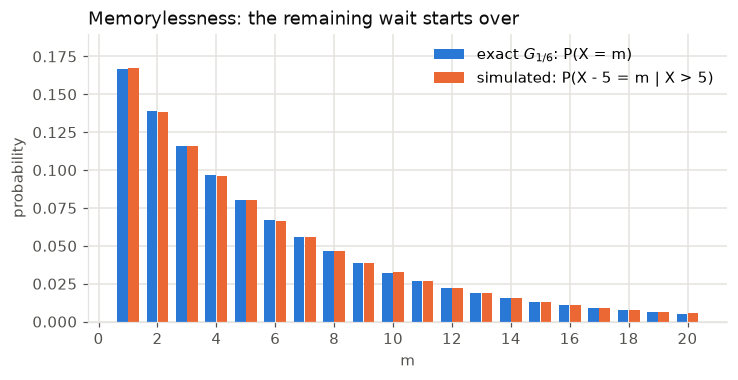

In [19]:
for n_ in [1, 5, 20]:
    for m in [1, 2, 7]:
        assert geometric(pf, n_ + m) / (1 - pf) ** n_ == geometric(pf, m)
print("P(X = n + m | X > n) = P(X = m) exactly for every n, m tried")

extra = first_six[first_six > 5] - 5
print(f"{extra.size} runs had no six in 5 rolls; extra rolls: mean {extra.mean():.4f} (1/p = 6), "
      f"P(extra = 1) = {np.mean(extra == 1):.4f} (p = {1 / 6:.4f})")

ms = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(ms - 0.19, [geometric(1 / 6, m) for m in ms], width=0.36, color=BLUE, label="exact $G_{1/6}$: P(X = m)")
ax.bar(ms + 0.19, [np.mean(extra == m) for m in ms], width=0.36, color=ORANGE,
       label="simulated: P(X - 5 = m | X > 5)")
ax.set(xticks=range(0, 21, 2), xlabel="m", ylabel="probability", ylim=(0, 0.19))
ax.legend(frameon=False)
ax.set_title("Memorylessness: the remaining wait starts over", color=INK, loc="left")
plt.show()